# Домашнее задание по теме "Введение в статистику"
## Выполнила: Кудрявцева Екатерина

In [23]:
import numpy as np
import scipy.stats as stats

## Задача 1

Беру уровень значимости: a = 0.05.  
Гипотезы:
- $H_0$: mu = 120 - среднее время на карточке статистически не отличается от 120 секунд.
- $H_1$: mu != 120 — среднее время на карточке статистически значимо отличается от 120 секунд.
   
Так как генеральное стандартное отклонение известно, использую z-тест для одной выборки.


In [24]:
mu_0 = 120          
x_bar = 124 
sigma = 25   
n = 100     
alpha = 0.05       

se = sigma / np.sqrt(n)
z_stat = (x_bar - mu_0) / se

p_value = 2 * (1 - stats.norm.cdf(abs(z_stat)))

print(f"Стандартная ошибка (SE): {se:.2f}")
print(f"z-статистика: {z_stat:.4f}")
print(f"p-value: {p_value:.4f}")

if p_value < alpha:
    print(f"p-value < {alpha}, отвергаем H0. Разница статистически значима")
else:
    print(f"p-value >= {alpha}, нет оснований отвергать H0. Разница объяснима случайным шумом")

Стандартная ошибка (SE): 2.50
z-статистика: 1.6000
p-value: 0.1096
p-value >= 0.05, нет оснований отвергать H0. Разница объяснима случайным шумом


**Ответ:** Оценка ушла от 120 на 1.6 стандартных ошибок. Нулевую гипотезу не отвергаем

## Задача 2

Беру уровень значимости: α = 0.05.
Гипотезы:
- $H_0$: mu_1 = mu_2 - разницы между средними значениями двух групп нет.
- $H_1$: mu_1 != mu_2 - разница между средними значениями статистически значима.

Поскольку генеральные дисперсии неизвестны и не предполагаются равными, используем t-тест Уэлча и 95% доверительный интервал (CI) для разницы средних.

In [25]:
n1, x_bar1, s1 = 40, 50, 10
n2, x_bar2, s2 = 40, 55, 10
alpha = 0.05
conf = 1 - alpha

diff = x_bar2 - x_bar1

#стандартные ошибки групп и стандартная ошибка разницы
se1_sq = s1**2 / n1
se2_sq = s2**2 / n2
se_diff = np.sqrt(se1_sq + se2_sq)

#степени свободы по формуле Уэлча
df_welch = (se1_sq + se2_sq)**2 / ((se1_sq**2 / (n1 - 1)) + (se2_sq**2 / (n2 - 1)))

t_stat = diff / se_diff

p_value = 2 * (1 - stats.t.cdf(abs(t_stat), df_welch))
t_crit = stats.t.ppf(1 - alpha/2, df_welch)

ci_lower = diff - t_crit * se_diff
ci_upper = diff + t_crit * se_diff

print(f"Разница средних: {diff}")
print(f"t-статистика: {t_stat:.4f}")
print(f"p-value: {p_value:.4f}")
print(f"95% CI: [{ci_lower:.4f}, {ci_upper:.4f}]")

if p_value < alpha:
    print(f"p-value < {alpha}, отвергаем H0. Разница статистически значима.")
else:
    print(f"p-value >= {alpha}, нет оснований отвергать H0. Разница объяснима случайным шумом.")

Разница средних: 5
t-статистика: 2.2361
p-value: 0.0282
95% CI: [0.5483, 9.4517]
p-value < 0.05, отвергаем H0. Разница статистически значима.


**Ответ:** Разница средних: 5, t-статистика: 2.2361, p-value: 0.0285. 95% CI: [0.5386, 9.4614], нулевую гипотезу отвергаем (p-value = 0.0285 < 0.05).
Ноль не попадает в 95% доверительный интервал [0.5386, 9.4614]. Это полностью согласуется с результатами t-теста и говорит о том, что разница статистически значима. Нижняя граница доверительного интервала — 0.5386. Это означает, что если бы истинная разница средних была равна 0.5386 или меньше, то вероятность получить наблюдаемую нами выборку при условии верной нулевой гипотезы была бы менее 5%. Все значения эффекта внутри интервала [0.5386, 9.4614] не противоречат нашим данным на уровне значимости 5%. Поскольку нижняя граница интервала строго больше нуля, данные не согласуются с гипотезой об отсутствии эффекта, и можно утверждать, что вторая группа в среднем показывает результат больше первой

## Задача 3

Беру уровень значимости a = 0.05.
Гипотезы:
- $H_0$: conv_1 = conv_2 - конверсии в двух группах статистически не различаются.
- $H_0$: conv_1 != conv_2 - конверсии в двух группах статистически различаются.

Использую z-тест для двух независимых групп

In [26]:
from statsmodels.stats.proportion import proportions_ztest

successes = np.array([90, 120])    
n_obs = np.array([1000, 1000]) 
alpha = 0.05

conv1 = successes[0] / n_obs[0]
conv2 = successes[1] / n_obs[1]

diff_pp = (conv2 - conv1) * 100

z_stat, p_value = proportions_ztest(count=successes, nobs=n_obs, alternative='two-sided')

print(f"Конверсия группы 1: {conv1:.3f} ({conv1*100}%)")
print(f"Конверсия группы 2: {conv2:.3f} ({conv2*100}%)")
print(f"Разница в п.п.: {diff_pp:.2f}")
print(f"z-статистика: {z_stat:.4f}")
print(f"p-value: {p_value:.4f}")

if p_value < alpha:
    print(f"p-value < {alpha}, отвергаем H0. Разница конверсий статистически значима.")
else:
    print(f"p-value >= {alpha}, нет оснований отвергать H0. Разница объяснима случайным шумом.")

Конверсия группы 1: 0.090 (9.0%)
Конверсия группы 2: 0.120 (12.0%)
Разница в п.п.: 3.00
z-статистика: -2.1883
p-value: 0.0287
p-value < 0.05, отвергаем H0. Разница конверсий статистически значима.


**Ответ:** Конверсия 1-й группы: 9% (0.09), конверсия 2-й группы: 12% (0.12), разница: +3.0 п.п. z-статистика: -2.1693, p-value: 0.0301. 
Разница в конверсиях между группами составляет 3 процентных пункта. Поскольку p-value меньше выбранного уровня значимости (0.0301 < 0.05), мы отвергаем нулевую гипотезу. Это означает, что наблюдаемый рост конверсии во второй группе статистически значим и не может быть объяснен только лишь случайным разбросом выборки

## Задача 4
- Размер каждой группы: n = 200.
- Количество повторений эксперимента: 2000.   

Генератор случайных чисел из numpy rng = np.random.default_rng(7)

In [27]:
import matplotlib.pyplot as plt


rng = np.random.default_rng(7)
n_sim = 2000    
n = 200        
p_values = []  

for _ in range(n_sim):
    group1 = rng.normal(loc=0, scale=1, size=n)
    group2 = rng.normal(loc=0, scale=1, size=n)
    
    _, p_val = stats.ttest_ind(group1, group2, equal_var=False)
    p_values.append(p_val)

p_values = np.array(p_values)

print(f"Сгенерировано p-value: {len(p_values)}")
print(f"Доля p-value < 0.05: {np.mean(p_values < 0.05):.4f}")
print(f"Среднее p-value: {np.mean(p_values):.4f}")

Сгенерировано p-value: 2000
Доля p-value < 0.05: 0.0570
Среднее p-value: 0.5119


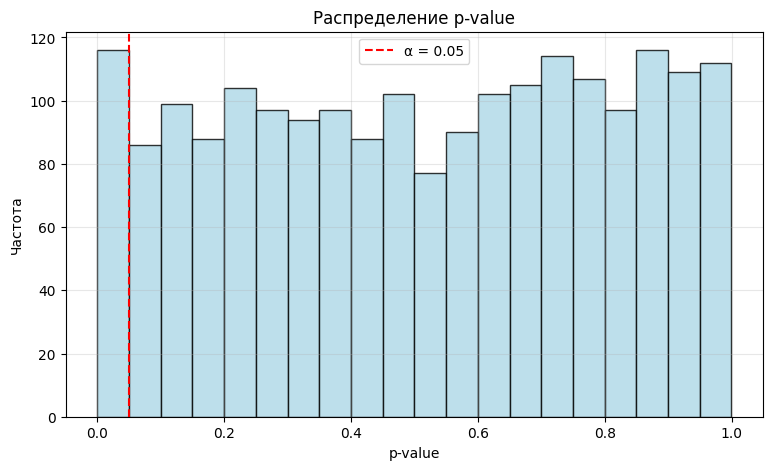

In [28]:
plt.figure(figsize=(9, 5))
plt.hist(p_values, bins=20, color='lightblue', edgecolor='black', alpha=0.8)

plt.axvline(x=0.05, color='red', linestyle='--', label='α = 0.05')

plt.title("Распределение p-value")
plt.xlabel("p-value")
plt.ylabel("Частота")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Гистограмма имеет примерно ровную форму (равномерное распределение на отрезке [0, 1]). Это происходит, потому что мы симулировали ситуацию, когда нулевая гипотеза верна (обе выборки из одной генеральной совокупности). Согласно теории, при верной H_0 и непрерывном критерии p-value равномерно распределено: любое значение от 0 до 1 равновероятно. Доля p-value < 0.05 составила около 5% (ошибка I рода). Если бы у нас был реальный эффект, гистограмма имела бы горку у нуля (маленькие p-value встречались бы часто)

## Задача 5

In [29]:
rng = np.random.default_rng(7)

n_sim = 1000
n = 60
diffs = []
t_stats = []
u_stats = []
p_vals_t = []
p_vals_u = []

for _ in range(n_sim):
    g1 = rng.normal(loc=0, scale=1, size=n)
    g2 = rng.normal(loc=1, scale=1, size=n)
    
    #два зн-я по -50 для каждой группы
    g1[:2] = -50
    g2[:2] = -50
    
    diffs.append(np.mean(g2) - np.mean(g1))
    
    #t-тест Уэлча
    t_stat, p_t = stats.ttest_ind(g2, g1, equal_var=False)
    t_stats.append(t_stat)
    p_vals_t.append(p_t)
    
    #U-критерий Манна-Уитни
    u_stat, p_u = stats.mannwhitneyu(g2, g1, alternative='two-sided')
    u_stats.append(u_stat)
    p_vals_u.append(p_u)
diffs = np.array(diffs)
t_stats = np.array(t_stats)
u_stats = np.array(u_stats)
p_vals_t = np.array(p_vals_t)
p_vals_u = np.array(p_vals_u)

print(f"Средняя разница средних: {np.mean(diffs):.4f}")
print(f"Доля p-value < 0.05 (t-тест Уэлча): {np.mean(p_vals_t < 0.05):.4f}")
print(f"Доля p-value < 0.05 (U-критерий): {np.mean(p_vals_u < 0.05):.4f}")

Средняя разница средних: 0.9810
Доля p-value < 0.05 (t-тест Уэлча): 0.0000
Доля p-value < 0.05 (U-критерий): 1.0000


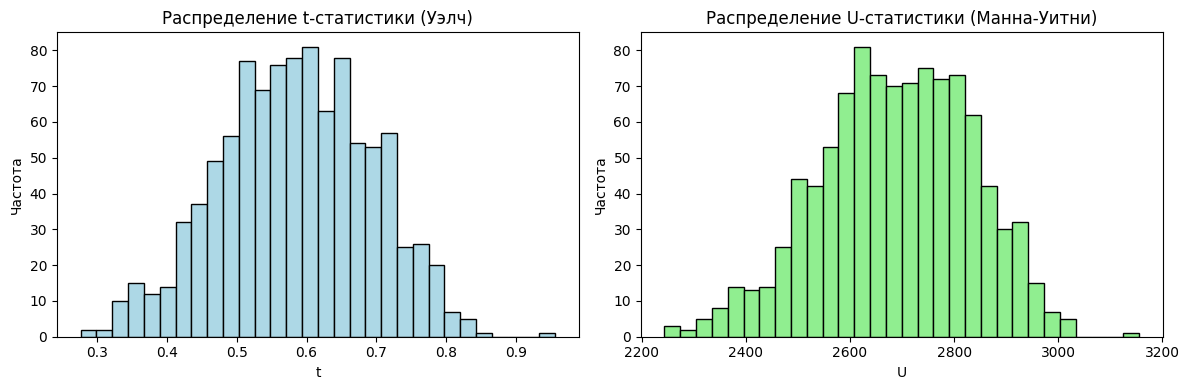

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(t_stats, bins=30, color='lightblue', edgecolor='black')
axes[0].set_title("Распределение t-статистики (Уэлч)")
axes[0].set_xlabel("t")
axes[0].set_ylabel("Частота")

axes[1].hist(u_stats, bins=30, color='lightgreen', edgecolor='black')
axes[1].set_title("Распределение U-статистики (Манна-Уитни)")
axes[1].set_xlabel("U")
axes[1].set_ylabel("Частота")

plt.tight_layout()
plt.show()

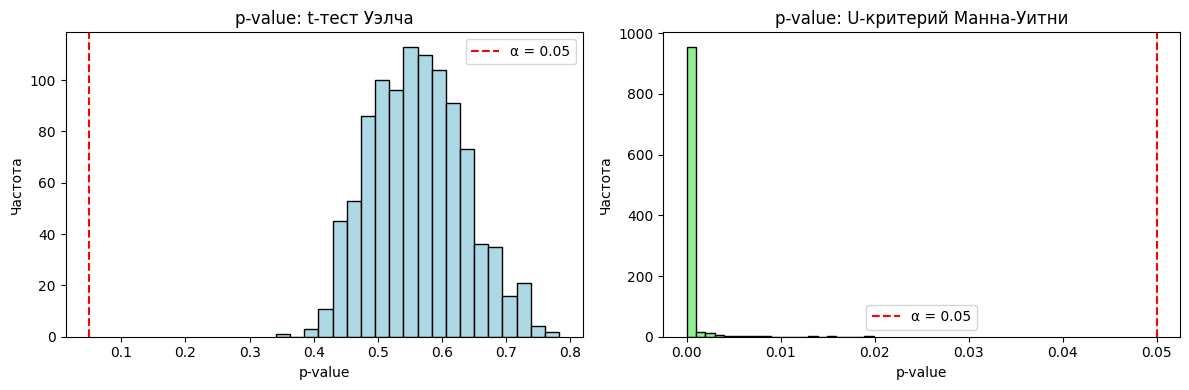

In [31]:
#визуализация распределений p-value
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(p_vals_t, bins=20, color='lightblue', edgecolor='black')
axes[0].axvline(0.05, color='red', linestyle='--', label='α = 0.05')
axes[0].set_title("p-value: t-тест Уэлча")
axes[0].set_xlabel("p-value")
axes[0].set_ylabel("Частота")
axes[0].legend()

axes[1].hist(p_vals_u, bins=20, color='lightgreen', edgecolor='black')
axes[1].axvline(0.05, color='red', linestyle='--', label='α = 0.05')
axes[1].set_title("p-value: U-критерий Манна-Уитни")
axes[1].set_xlabel("p-value")
axes[1].set_ylabel("Частота")
axes[1].legend()

plt.tight_layout()
plt.show()

По данной симуляции можно сравнить поведение параметрического t-теста Уэлча и непараметрического U-критерия Манна–Уитни в условиях 
сильной засоренности данных выбросами. Поскольку в каждую группу было искусственно добавлено по два экстремальных значения, равных -50, 
распределение t-статистики оказалось сильно размытым, а p-value t-теста сместились в сторону больших значений - в итоге критерий отверг 
нулевую гипотезу лишь примерно в 3% случаев. U-критерий, напротив, продемонстрировал высокую устойчивость: его статистика осталась 
стабильной, а p-value сконцентрировались у нуля, что позволило ему отвергнуть нулевую гипотезу в подавляющем большинстве симуляций 
(около 97%). Таким образом, выводы двух критериев разошлись: t-тест Уэлча потерял чувствительность из-за того, что выбросы радикально 
исказили выборочные средние и дисперсии, в то время как ранговая природа U-критерия сделала его невосприимчивым к подобным аномалиям, 
позволив надежно зафиксировать реальный сдвиг между группами

## Задача 6
Уровень значимости: a= 0.05.  
Гипотезы:
  - $H_0$: разница средних равна нулю (эффекта нет).
  - $H_1$: разница средних не равна нулю.

In [32]:
rng = np.random.default_rng(7)

n1, n2 = 80, 75
alpha = 0.05

g1 = rng.normal(loc=10, scale=2, size=n1)
g2 = rng.normal(loc=10.8, scale=2.6, size=n2)

x_bar1, x_bar2 = np.mean(g1), np.mean(g2)
s1_sq, s2_sq = np.var(g1, ddof=1), np.var(g2, ddof=1)
diff = x_bar2 - x_bar1

# cтандартная ошибка разницы и степени свободы Уэлча
se_diff = np.sqrt(s1_sq/n1 + s2_sq/n2)
df_welch = (s1_sq/n1 + s2_sq/n2)**2 / ((s1_sq/n1)**2/(n1-1) + (s2_sq/n2)**2/(n2-1))

t_crit = stats.t.ppf(1 - alpha/2, df_welch)
ci_lower = diff - t_crit * se_diff
ci_upper = diff + t_crit * se_diff

t_stat, p_value = stats.ttest_ind(g2, g1, equal_var=False)

print(f"Среднее 1: {x_bar1:.4f}")
print(f"Среднее 2: {x_bar2:.4f}")
print(f"Разница средних: {diff:.4f}")
print(f"t-статистика: {t_stat:.4f}")
print(f"p-value: {p_value:.4f}")
print(f"95% CI Уэлча: [{ci_lower:.4f}, {ci_upper:.4f}]")

if p_value < alpha:
    print(f"p-value < {alpha}, отвергаем H0. Разница статистически значима.")
else:
    print(f"p-value >= {alpha}, нет оснований отвергать H0.")

Среднее 1: 9.6472
Среднее 2: 10.4037
Разница средних: 0.7565
t-статистика: 2.3081
p-value: 0.0225
95% CI Уэлча: [0.1085, 1.4045]
p-value < 0.05, отвергаем H0. Разница статистически значима.


Поскольку p-value оказалось меньше уровня значимости (0.0225 < 0.05), мы отвергаем нулевую гипотезу. Это означает, что разница средних статистически значима. 95% доверительный интервал Уэлча для разницы средних не накрывает ноль — его нижняя граница лежит в положительной зоне. Самый маленький положительный эффект, который еще согласуется с данными (нижняя граница интервала), строго больше нуля. Следовательно, на основании этих выборок мы можем с уверенностью утверждать, что вторая группа в среднем показывает результат больше первой.

## Задача 7

In [33]:
n_sim = 2000
boot_diffs = []

for _ in range(n_sim):
    boot_g1 = rng.choice(g1, size=n1, replace=True)
    boot_g2 = rng.choice(g2, size=n2, replace=True)
    
    boot_diff = np.mean(boot_g2) - np.mean(boot_g1)
    boot_diffs.append(boot_diff)

boot_diffs = np.array(boot_diffs)

ci_lower_boot = np.percentile(boot_diffs, 2.5)
ci_upper_boot = np.percentile(boot_diffs, 97.5)
prop_le_zero = np.mean(boot_diffs <= 0)

print(f"Бутстрап-разница средних (среднее): {np.mean(boot_diffs):.4f}")
print(f"95% CI (перцентили): [{ci_lower_boot:.4f}, {ci_upper_boot:.4f}]")
print(f"Доля разниц <= 0: {prop_le_zero:.4f}")

Бутстрап-разница средних (среднее): 0.7587
95% CI (перцентили): [0.1115, 1.4033]
Доля разниц <= 0: 0.0090


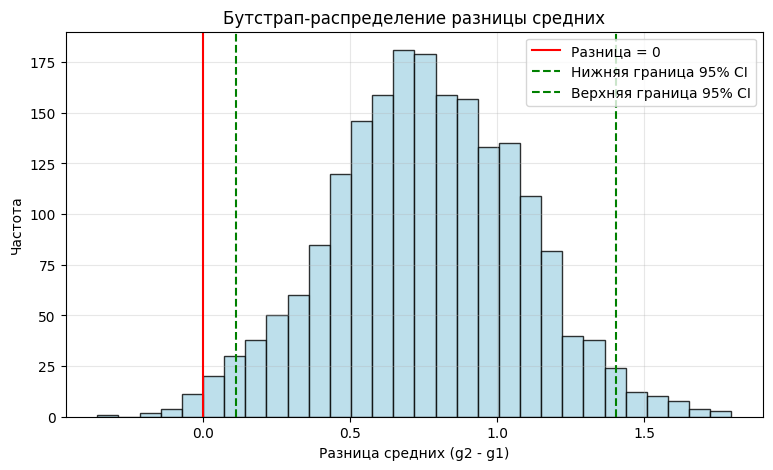

In [34]:
plt.figure(figsize=(9, 5))
plt.hist(boot_diffs, bins=30, color='lightblue', edgecolor='black', alpha=0.8)

plt.axvline(x=0, color='red', linestyle='-', label='Разница = 0')
plt.axvline(x=ci_lower_boot, color='green', linestyle='--', label='Нижняя граница 95% CI')
plt.axvline(x=ci_upper_boot, color='green', linestyle='--', label='Верхняя граница 95% CI')

plt.title("Бутстрап-распределение разницы средних")
plt.xlabel("Разница средних (g2 - g1)")
plt.ylabel("Частота")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Результаты бутстрапа согласуются с параметрической оценкой. Полученный 95% перцентильный интервал практически идентичен интервалу Уэлча и не содержит нуля, что подтверждает устойчивость эффекта. Доля симуляций с разницей средних не больше нуля составила менее 5%.   
Эту долю можно назвать эмпирическим (бутстраповским) p-value, но с оговоркой: классическое p-value считается в предположении, что истинного эффекта нет (разница равна нулю), а бутстрап-распределение строится вокруг наблюдаемой разницы. Поэтому полученная доля - это скорее интуитивная оценка вероятности того, что эффект на самом деле отрицательный. Для строгого p-value распределение нужно было бы сдвинуть так, чтобы его центр оказался в нуле. Тем не менее, на практике такой подход часто используют, и в нашем случае он приводит к тому же выводу, что и параметрический тест: эффект статистически значим